In [1]:
!pip -q install gensim

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import gensim.downloader as api
from sklearn.decomposition import PCA

In [3]:
glove = api.load("glove-wiki-gigaword-50")
print("Vocabulary size :", len(glove.key_to_index))
print("Vector dimension:", glove.vector_size)

[==================================================] 100.0% 66.0/66.0MB downloaded
Vocabulary size : 400000
Vector dimension: 50


In [4]:
v = glove["computer"]
print("Shape:", v.shape)
print("Vector for 'computer':\n", v.round(3))

Shape: (50,)
Vector for 'computer':
 [ 0.079 -0.815  1.79   0.917  0.108 -0.556 -0.844 -1.495  0.134  0.636
  0.351  0.258 -0.55   0.511  0.374  0.121 -1.617  0.837  0.142 -0.523
  0.735  0.122 -0.491  0.325  0.453 -1.585 -0.638 -1.005  0.105 -0.43
  3.181 -0.622  0.168 -1.014  0.064  0.578 -0.456  0.738  0.372 -0.577
  0.664  0.055  0.038  1.328  0.31   0.507  1.236  0.127 -0.114  0.207]


In [5]:
print("similarity(king, queen) =", round(float(glove.similarity("king", "queen")), 3))
print("similarity(king, apple) =", round(float(glove.similarity("king", "apple")), 3))
print("\nNearest to 'india':", glove.most_similar("india", topn=5))
print("\nAnalogy king - man + woman =", glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3))
print("Analogy paris - france + italy =", glove.most_similar(positive=["paris", "italy"], negative=["france"], topn=3))

similarity(king, queen) = 0.784
similarity(king, apple) = 0.305

Nearest to 'india': [('indian', 0.8648794293403625), ('pakistan', 0.8529723286628723), ('malaysia', 0.816650927066803), ('bangladesh', 0.8154239058494568), ('delhi', 0.8142766356468201)]

Analogy king - man + woman = [('queen', 0.8523604273796082), ('throne', 0.7664334177970886), ('prince', 0.7592144012451172)]
Analogy paris - france + italy = [('rome', 0.8465589284896851), ('milan', 0.7766007781028748), ('turin', 0.7666355967521667)]


In [6]:
def sent_vec(s):
    vs = [glove[w] for w in s.lower().split() if w in glove]
    return np.mean(vs, axis=0)

a = sent_vec("the movie was great")
b = sent_vec("the film was excellent")
c = sent_vec("the stock market crashed today")
cos = lambda x, y: float(np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y)))
print("movie/film  :", round(cos(a, b), 3))
print("movie/stock :", round(cos(a, c), 3))

movie/film  : 0.964
movie/stock : 0.753


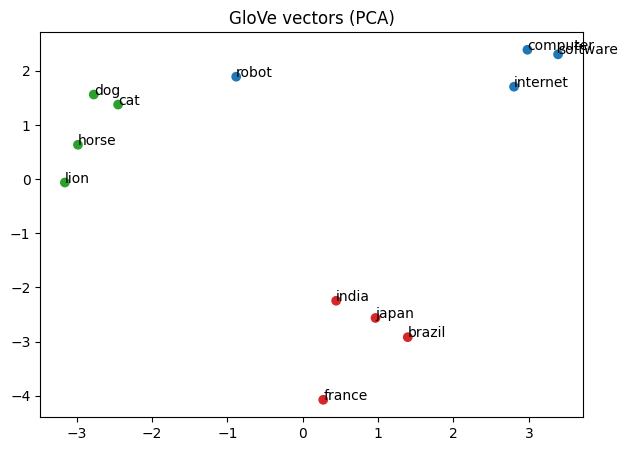

In [7]:
groups = {"countries": ["india", "france", "japan", "brazil"],
          "animals": ["dog", "cat", "horse", "lion"],
          "tech": ["computer", "software", "internet", "robot"]}
words = [w for g in groups.values() for w in g]
pts = PCA(n_components=2).fit_transform([glove[w] for w in words])
plt.figure(figsize=(7, 5))
colors = ["tab:red"]*4 + ["tab:green"]*4 + ["tab:blue"]*4
plt.scatter(pts[:, 0], pts[:, 1], c=colors)
for w, (x, y) in zip(words, pts): plt.annotate(w, (x, y))
plt.title("GloVe vectors (PCA)"); plt.show()